## 1. Імпорт бібліотек і персональні параметри

`SEED = 1000 × VARIANT + STUDENT_ID`

In [1]:
import os, re, time, hashlib, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import pytesseract
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

STUDENT = "Курилів В. І."
VARIANT = 7
STUDENT_ID = 574
SEED = 1000 * VARIANT + STUDENT_ID
rng = np.random.default_rng(SEED)

FONTS = [
    "/System/Library/Fonts/Supplemental/Arial.ttf",
    "/System/Library/Fonts/Supplemental/Times New Roman.ttf",
    "/System/Library/Fonts/Supplemental/Georgia.ttf",
    "/System/Library/Fonts/Supplemental/Verdana.ttf",
]
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print("SEED =", SEED)
print("Tesseract", pytesseract.get_tesseract_version(), "| мови:",
      [l for l in pytesseract.get_languages() if l in ("ukr", "eng")])
print("Шрифти є:", all(os.path.exists(f) for f in FONTS))

SEED = 7574
Tesseract 5.5.3 | мови: ['eng', 'ukr']
Шрифти є: True


## 2. Формування синтетичного набору з еталонною розміткою

Джерело тексту: Г. Квітка-Основ'яненко, «Маруся», https://www.ukrlib.com.ua/books/printit.php?tid=1018

Підготовка `corpus.txt`:
- у тексті на сайті замість кириличної «і» стоїть латинська «i», тому латинські `i`/`I` замінено на кириличні `і`/`І`
- текст розбито на речення, залишено речення довжиною 20–70 символів

Вибираємо 40 речень і відтворюємо кожне на 7 рівнях гаусового розмиття

In [2]:
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]
lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]
print("Речень у corpus.txt:", len(corpus), "| вибрано:", len(lines))

Речень у corpus.txt: 759 | вибрано: 40


In [ ]:
def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

def degrade(img, kind, level, rng):
    out = img.astype(np.float32)
    if kind == "blur" and level > 0:
        out = cv2.GaussianBlur(out, (0, 0), level)
    return np.clip(out, 0, 255).astype(np.uint8)

In [4]:
FACTOR, LEVELS = "blur", [0, 0.5, 1, 1.5, 2, 2.5, 3]
records = []
for i, text in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    clean = render_line(text, font, size=int(rng.integers(22, 36)))
    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
        records.append({"id": i, "level": lvl, "path": path, "gt": text,
                        "font": os.path.basename(font)})
ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)
with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()[:16]
print("Записів:", len(ds), "| SHA-256 еталону:", sha)

Записів: 280 | SHA-256 еталону: 120b7a735fea41c0


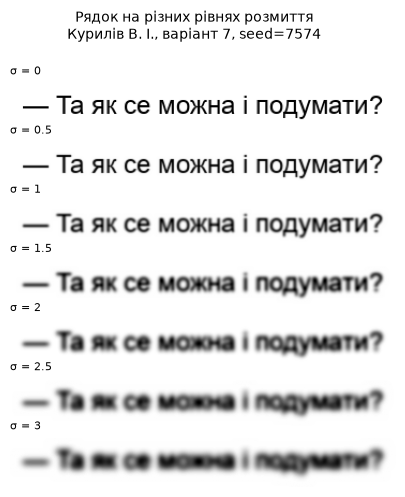

In [16]:
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(7, 0.75 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"σ = {lvl}", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Рядок на різних рівнях розмиття\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10, y=1.02)
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")